# Hybrid post-quantum TLS handshakes from qBraid

**Purpose:** measure what X25519MLKEM768 (classical X25519 + ML-KEM-768, FIPS 203) costs compared with classical X25519 in real TLS 1.3 handshakes against public servers that support it. Every run happens in **qBraid Lab** (one cloud vantage, Cloudflare IAD edge). The 1 October 2026 run is session 1; further sessions are repeated on different days and at different times of day.

What each session records, per handshake:
- whether the server accepted the group (and which group was negotiated)
- wall-clock handshake time, with OpenSSL start-up overhead subtracted
- bytes the client sent and received during the handshake
- a separate TCP connection time and name-lookup time to the same server

**How to run a new session:** run sections **0 → 1 → 2**, skip 3, then run **4**. Run **5** once. Run **6** after the last session. Don't use Run All.

Sections: **0** settings · **1** set up (packages, OpenSSL 3.5+) · **2** sanity check · **3** session 1, 1 Oct 2026 (done; don't re-run) · **4** repeat sessions · **5** ClientHello size check · **6** paired and multi-session analysis · **7** notes for the write-up

## 0 · Settings

In [1]:
# Keep this label exactly as it is for every session: the analysis in section 6
# only pools sessions with this label.
VANTAGE = "qBraid cloud"

# Public servers that offer X25519MLKEM768. Don't change these between sessions.
HOSTS = ["cloudflare.com", "www.google.com", "pq.cloudflareresearch.com"]

# Key-exchange groups to compare.
GROUPS = ["X25519", "X25519MLKEM768"]

ROUNDS = 30            # handshakes per host per group per session (a few minutes per session)
TIMEOUT_S = 20
PAUSE_S = 0.2          # small gap between handshakes to be polite to servers

# Optional: full path to an OpenSSL 3.5+ binary if you already have one.
OPENSSL_BIN = None

## 1 · Set up: Python packages and OpenSSL 3.5+
The first cell installs pandas, matplotlib and scipy (needed by sections 5 and 6). The second finds the OpenSSL 3.5.4 built in your qBraid home folder on 1 October (`~/pqc_openssl`), or builds it again if it's missing (conda first, source build as a fallback, about 5–10 minutes). Nothing system-wide is changed.

In [2]:
%pip install -q pandas matplotlib scipy

Note: you may need to restart the kernel to use updated packages.


In [3]:
import os, re, shutil, subprocess, sys, platform, tarfile, urllib.request
from pathlib import Path

HOME = Path.home()
PREFIX = HOME / "pqc_openssl"

def ossl_version(binary):
    try:
        out = subprocess.run([binary, "version"], capture_output=True, text=True, timeout=10).stdout
        m = re.search(r"OpenSSL (\d+)\.(\d+)\.(\d+)", out)
        return (tuple(int(x) for x in m.groups()), out.strip()) if m else (None, out.strip())
    except Exception as e:
        return None, str(e)

def good(binary):
    v, _ = ossl_version(binary)
    return v is not None and v >= (3, 5, 0)

candidates = [OPENSSL_BIN, str(PREFIX / "bin" / "openssl"), shutil.which("openssl")]
OPENSSL = next((c for c in candidates if c and Path(c).exists() and good(c)), None)

if OPENSSL is None:
    conda = shutil.which("mamba") or shutil.which("conda")
    if conda:
        print("Installing OpenSSL 3.5+ with", conda, "into", PREFIX, "...")
        r = subprocess.run([conda, "create", "-y", "-p", str(PREFIX), "-c", "conda-forge", "openssl>=3.5"],
                           capture_output=True, text=True)
        print(r.stdout[-1500:], r.stderr[-1500:])
        if good(str(PREFIX / "bin" / "openssl")):
            OPENSSL = str(PREFIX / "bin" / "openssl")

if OPENSSL is None:
    print("Building OpenSSL 3.5.4 from source (5-10 minutes) ...")
    ver = "3.5.4"
    src = HOME / f"openssl-{ver}"
    tgz = HOME / f"openssl-{ver}.tar.gz"
    if not tgz.exists():
        urllib.request.urlretrieve(f"https://github.com/openssl/openssl/releases/download/openssl-{ver}/openssl-{ver}.tar.gz", tgz)
    if not src.exists():
        with tarfile.open(tgz) as t:
            t.extractall(HOME)
    jobs = str(os.cpu_count() or 2)
    steps = [["./Configure", f"--prefix={PREFIX}", "--libdir=lib", f"-Wl,-rpath,{PREFIX}/lib", "no-tests", "no-docs"],
             ["make", f"-j{jobs}"], ["make", "install_sw"]]
    for s in steps:
        r = subprocess.run(s, cwd=src, capture_output=True, text=True)
        if r.returncode != 0:
            print(r.stdout[-2000:], r.stderr[-2000:])
            raise SystemExit("Build step failed: " + " ".join(s))
    OPENSSL = str(PREFIX / "bin" / "openssl")

print("Using:", OPENSSL)
print(ossl_version(OPENSSL)[1])

Using: /home/jovyan/pqc_openssl/bin/openssl
OpenSSL 3.5.4 30 Sep 2025 (Library: OpenSSL 3.5.4 30 Sep 2025)


## 2 · Sanity check
One handshake per host and group. Expect `X25519MLKEM768` to be negotiated where the server supports it.

In [4]:
import time, socket, statistics, random, csv, datetime as dt

RE_BYTES = re.compile(r"SSL handshake has read (\d+) bytes and written (\d+) bytes")
RE_GROUP = re.compile(r"(?:Negotiated TLS1\.3 group|Server Temp Key|Peer Temp Key):\s*([A-Za-z0-9_\-]+)")
RE_PROTO = re.compile(r"Protocol\s*:\s*(TLSv[0-9.]+)|New, (TLSv[0-9.]+)")

def handshake(host, group):
    cmd = [OPENSSL, "s_client", "-connect", f"{host}:443", "-servername", host,
           "-groups", group, "-tls1_3"]
    t0 = time.perf_counter()
    try:
        r = subprocess.run(cmd, input="", capture_output=True, text=True, timeout=TIMEOUT_S)
        out = r.stdout + r.stderr
    except subprocess.TimeoutExpired:
        return dict(ok=False, total_ms=None, read=None, written=None, negotiated="timeout")
    total_ms = (time.perf_counter() - t0) * 1000
    b = RE_BYTES.search(out)
    g = RE_GROUP.search(out)
    ok = b is not None and int(b.group(1)) > 0 and "handshake failure" not in out.lower()
    return dict(ok=ok, total_ms=total_ms,
                read=int(b.group(1)) if b else None,
                written=int(b.group(2)) if b else None,
                negotiated=g.group(1) if g else ("" if ok else "failed"))

def tcp_rtt_ms(host):
    t0 = time.perf_counter()
    with socket.create_connection((host, 443), timeout=TIMEOUT_S):
        pass
    return (time.perf_counter() - t0) * 1000

def process_overhead_ms(n=15):
    xs = []
    for _ in range(n):
        t0 = time.perf_counter()
        subprocess.run([OPENSSL, "version"], capture_output=True)
        xs.append((time.perf_counter() - t0) * 1000)
    return statistics.median(xs)

def cloudflare_colo():
    try:
        with urllib.request.urlopen("https://cloudflare.com/cdn-cgi/trace", timeout=10) as f:
            m = re.search(r"colo=(\w+)", f.read().decode())
            return m.group(1) if m else ""
    except Exception:
        return ""

for h in HOSTS:
    for g in GROUPS:
        r = handshake(h, g)
        print(f"{h:28s} {g:16s} ok={r['ok']!s:5s} negotiated={r['negotiated']:16s} "
              f"sent={r['written']} recv={r['read']}")

cloudflare.com               X25519           ok=True  negotiated=X25519           sent=320 recv=2877
cloudflare.com               X25519MLKEM768   ok=True  negotiated=X25519MLKEM768   sent=1496 recv=3964
www.google.com               X25519           ok=True  negotiated=X25519           sent=320 recv=2779
www.google.com               X25519MLKEM768   ok=True  negotiated=X25519MLKEM768   sent=1496 recv=3866
pq.cloudflareresearch.com    X25519           ok=True  negotiated=X25519           sent=331 recv=2836
pq.cloudflareresearch.com    X25519MLKEM768   ok=True  negotiated=X25519MLKEM768   sent=1507 recv=3925


## 3 · Session 1 — 1 October 2026 (done; don't re-run)
The original measurement. Its output is kept below as the record of session 1, and its data is `results_qBraid_cloud.csv`. If this cell is run by mistake it will not overwrite that file: the new run is saved in `sessions/` instead.

In [4]:
OVERHEAD_MS = process_overhead_ms()
COLO = cloudflare_colo()
print(f"OpenSSL start-up overhead ≈ {OVERHEAD_MS:.1f} ms · Cloudflare edge serving this run: {COLO or 'unknown'}")

rows = []
started = dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds")
for i in range(ROUNDS):
    jobs = [(h, g) for h in HOSTS for g in GROUPS]
    random.shuffle(jobs)
    for h, g in jobs:
        try:
            rtt = tcp_rtt_ms(h)
        except Exception:
            rtt = None
        r = handshake(h, g)
        rows.append(dict(vantage=VANTAGE, utc_start=started, round=i, host=h, group=g,
                         ok=r["ok"], negotiated=r["negotiated"],
                         total_ms=r["total_ms"],
                         handshake_ms=(r["total_ms"] - OVERHEAD_MS) if r["total_ms"] else None,
                         tcp_rtt_ms=rtt, bytes_sent=r["written"], bytes_recv=r["read"],
                         overhead_ms=OVERHEAD_MS, cf_colo=COLO))
        time.sleep(PAUSE_S)
    print(f"round {i+1}/{ROUNDS} done")

safe = re.sub(r"[^A-Za-z0-9]+", "_", VANTAGE).strip("_")
OUT = Path(f"results_{safe}.csv")
if OUT.exists():   # never overwrite an earlier run; store this one as an extra session
    Path("sessions").mkdir(exist_ok=True)
    OUT = Path("sessions") / f"session_{safe}_{started[:19].replace('-', '').replace(':', '')}Z.csv"
    print(f"results_{safe}.csv already exists, so this run is saved as a session instead.")
with open(OUT, "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
    w.writeheader(); w.writerows(rows)
print("Saved", OUT.resolve())

OpenSSL start-up overhead ≈ 2.0 ms · Cloudflare edge serving this run: IAD
round 1/30 done
round 2/30 done
round 3/30 done
round 4/30 done
round 5/30 done
round 6/30 done
round 7/30 done
round 8/30 done
round 9/30 done
round 10/30 done
round 11/30 done
round 12/30 done
round 13/30 done
round 14/30 done
round 15/30 done
round 16/30 done
round 17/30 done
round 18/30 done
round 19/30 done
round 20/30 done
round 21/30 done
round 22/30 done
round 23/30 done
round 24/30 done
round 25/30 done
round 26/30 done
round 27/30 done
round 28/30 done
round 29/30 done
round 30/30 done
Saved /home/jovyan/results_qBraid_cloud.csv


## 4 · Repeat sessions
Run this cell once per session, at different times of day, without changing any setting in section 0. Each session takes a few minutes and is saved to `sessions/` under its own timestamp, so nothing is overwritten. The 1 October file stays as session 1.

**Suggested weekend schedule** (6 sessions): Saturday morning, afternoon and late evening; Sunday the same. Put a short label in `SESSION_NOTE` (e.g. `"Sat AM"`).

**Each session:** run sections 0, 1 and 2 (they set up `OPENSSL` and the helper functions), skip section 3, then run this cell. If the kernel is still running from an earlier session, you can run this cell on its own. New in these files: a `dns_ms` column (name-lookup time measured on its own), `session_id`, `order_in_round` and the OpenSSL version string.

In [5]:
# ── 4 · Repeat sessions ─────────────────────────────────────────────────
# Run this cell once per session (e.g. Saturday morning, afternoon, evening;
# Sunday the same). Every session uses the SAME hosts, groups, rounds and
# OpenSSL binary as the 1 October run, so all sessions are comparable.
# Each session is saved as its own file in ./sessions/ and is never overwritten.
#
# Optional: set N_SESSIONS > 1 to run several sessions back to back with a gap
# between them (only if your qBraid kernel stays alive while you are away).

N_SESSIONS = 1          # sessions to run now
GAP_MINUTES = 0         # wait between sessions when N_SESSIONS > 1
SESSION_NOTE = "Sun late"       # free text, e.g. "Sat morning" (stored in the CSV)

SESS_DIR = Path("sessions"); SESS_DIR.mkdir(exist_ok=True)
OSSL_VERSION = ossl_version(OPENSSL)[1]

def dns_ms(host):
    """Time to resolve the host name alone. Recorded separately because
    tcp_rtt_ms and the s_client run both include a lookup."""
    t0 = time.perf_counter()
    socket.getaddrinfo(host, 443, type=socket.SOCK_STREAM)
    return (time.perf_counter() - t0) * 1000

def run_session(note=""):
    overhead = process_overhead_ms()
    colo = cloudflare_colo()
    start = dt.datetime.now(dt.timezone.utc)
    sid = start.strftime("%Y%m%dT%H%M%SZ")
    print(f"Session {sid} · overhead ≈ {overhead:.1f} ms · Cloudflare edge {colo or 'unknown'}")
    out = []
    for i in range(ROUNDS):
        jobs = [(h, g) for h in HOSTS for g in GROUPS]
        random.shuffle(jobs)
        for order, (h, g) in enumerate(jobs):
            try:
                dns = dns_ms(h)
            except Exception:
                dns = None
            try:
                rtt = tcp_rtt_ms(h)
            except Exception:
                rtt = None
            r = handshake(h, g)
            out.append(dict(vantage=VANTAGE, utc_start=start.isoformat(timespec="seconds"),
                            session_id=sid, session_note=note, round=i, order_in_round=order,
                            host=h, group=g, ok=r["ok"], negotiated=r["negotiated"],
                            total_ms=r["total_ms"],
                            handshake_ms=(r["total_ms"] - overhead) if r["total_ms"] else None,
                            tcp_rtt_ms=rtt, dns_ms=dns,
                            bytes_sent=r["written"], bytes_recv=r["read"],
                            overhead_ms=overhead, cf_colo=colo, openssl=OSSL_VERSION))
            time.sleep(PAUSE_S)
        if (i + 1) % 10 == 0:
            print(f"  round {i+1}/{ROUNDS}")
    path = SESS_DIR / f"session_{re.sub(r'[^A-Za-z0-9]+', '_', VANTAGE)}_{sid}.csv"
    with open(path, "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(out[0].keys()))
        w.writeheader(); w.writerows(out)
    n_ok = sum(x["ok"] for x in out)
    print(f"  saved {path} · {n_ok}/{len(out)} handshakes ok")
    return path

for k in range(N_SESSIONS):
    run_session(SESSION_NOTE)
    if k < N_SESSIONS - 1 and GAP_MINUTES > 0:
        print(f"Waiting {GAP_MINUTES} min before the next session ...")
        time.sleep(GAP_MINUTES * 60)

print("Sessions on disk:", len(list(SESS_DIR.glob("session_*.csv"))))

Session 20261123T045556Z · overhead ≈ 1.6 ms · Cloudflare edge IAD
  round 10/30
  round 20/30
  round 30/30
  saved sessions/session_qBraid_cloud_20261123T045556Z.csv · 180/180 handshakes ok
Sessions on disk: 6


## 5 · ClientHello / ServerHello size check (run once)
Records the handshake message lengths with `s_client -msg` so the byte overhead can be compared with the sizes RFC 10024 specifies (+1,184 bytes in the client key share, +1,088 in the server key share). The 1 October data showed +1,176 sent, 8 bytes short of the key-share increase; this cell shows which message accounts for it. It also flags any HelloRetryRequest.

In [7]:
import pandas as pd
# ── 5 · ClientHello / ServerHello size check ───────────────────────────
# Explains the byte counts. RFC 10024 predicts the hybrid client key share is
# 1,184 bytes larger (ML-KEM-768 encapsulation key) and the server key share
# 1,088 bytes larger (ML-KEM-768 ciphertext). This cell records the actual
# handshake-message lengths with `s_client -msg` so any gap can be traced
# to a specific message. One handshake per host and group; run once.

RE_MSG = re.compile(r"^(>>>|<<<)\s+(TLS [0-9.]+|\?\?\?)?.*?Handshake\s*\[length ([0-9a-fA-F]+)\],\s*(\w+)", re.M)

def hello_sizes(host, group):
    cmd = [OPENSSL, "s_client", "-connect", f"{host}:443", "-servername", host,
           "-groups", group, "-tls1_3", "-msg"]
    r = subprocess.run(cmd, input="", capture_output=True, text=True, timeout=TIMEOUT_S)
    out = r.stdout + r.stderr
    msgs = {}
    for direction, _, length, name in RE_MSG.findall(out):
        key = ("C:" if direction == ">>>" else "S:") + name
        msgs.setdefault(key, int(length, 16))          # first occurrence
    b = RE_BYTES.search(out)
    return dict(host=host, group=group,
                client_hello=msgs.get("C:ClientHello"), server_hello=msgs.get("S:ServerHello"),
                hello_retry=("S:HelloRetryRequest" in msgs) or ("HelloRetryRequest" in out),
                written=int(b.group(2)) if b else None, read=int(b.group(1)) if b else None,
                raw=out)

hello = [hello_sizes(h, g) for h in HOSTS for g in GROUPS]
hello_df = pd.DataFrame([{k: v for k, v in x.items() if k != "raw"} for x in hello])
display(hello_df)

d = hello_df.pivot(index="host", columns="group",
                   values=["client_hello", "server_hello", "written", "read"])
check = pd.DataFrame({
    "ClientHello +bytes": d["client_hello"]["X25519MLKEM768"] - d["client_hello"]["X25519"],
    "expected (key share)": 1184,
    "ServerHello +bytes": d["server_hello"]["X25519MLKEM768"] - d["server_hello"]["X25519"],
    "expected (ciphertext)": 1088,
    "written +bytes": d["written"]["X25519MLKEM768"] - d["written"]["X25519"],
    "read +bytes": d["read"]["X25519MLKEM768"] - d["read"]["X25519"],
})
display(check)
hello_df.to_csv("hello_sizes.csv", index=False)
with open("hello_sizes_raw.txt", "w") as f:
    for x in hello:
        f.write(f"===== {x['host']} {x['group']}\n{x['raw']}\n")
print("Saved hello_sizes.csv and hello_sizes_raw.txt (full -msg output, for the appendix)")
if hello_df.client_hello.isna().any():
    print("Note: some message lengths were not parsed; open hello_sizes_raw.txt and search for 'ClientHello'.")

,host,group,client_hello,server_hello,hello_retry,written,read
0,cloudflare.com,X25519,235,122,False,320,2877
1,cloudflare.com,X25519MLKEM768,1411,1210,False,1496,3965
2,www.google.com,X25519,235,122,False,320,2778
3,www.google.com,X25519MLKEM768,1411,1210,False,1496,3866
4,pq.cloudflareresearch.com,X25519,246,122,False,331,2828
5,pq.cloudflareresearch.com,X25519MLKEM768,1422,1210,False,1507,3916


,ClientHello +bytes,expected (key share),ServerHello +bytes,expected (ciphertext),written +bytes,read +bytes
host,,,,,,
cloudflare.com,1176,1184,1088,1088,1176,1088
pq.cloudflareresearch.com,1176,1184,1088,1088,1176,1088
www.google.com,1176,1184,1088,1088,1176,1088


Saved hello_sizes.csv and hello_sizes_raw.txt (full -msg output, for the appendix)


### Session housekeeping (21 November 2026)
A section 4 run started at 17:36:44 UTC without a `SESSION_NOTE` duplicated the Saturday-morning session that began 45 seconds later. The two cells below list the session files and move the duplicate to `sessions_excluded/`, so section 6 does not count it. The file is kept for transparency.

In [8]:
import pandas as pd, glob
for f in sorted(glob.glob("sessions/*.csv")):
    x = pd.read_csv(f)
    print(f, len(x), "rows,", x.ok.sum(), "ok, note:", x.get("session_note", pd.Series(["(none)"])).iloc[0])

sessions/session_qBraid_cloud_20261121T173644Z.csv 180 rows, 180 ok, note: nan
sessions/session_qBraid_cloud_20261121T173729Z.csv 180 rows, 180 ok, note: SAT AM


In [9]:
import shutil, os
os.makedirs("sessions_excluded", exist_ok=True)
shutil.move("sessions/session_qBraid_cloud_20261121T173644Z.csv", "sessions_excluded/")

'sessions_excluded/session_qBraid_cloud_20261121T173644Z.csv'

## 6 · Paired and multi-session analysis (run after the last session)
Reads `results_qBraid_cloud.csv` plus everything in `sessions/`. Classical and hybrid are paired within each (session, round, host), and intervals come from a two-stage bootstrap (sessions, then rounds; fixed seed 20261119). The unpaired bootstrap used in the manuscript is reported alongside for continuity. Writes `per_session_summary.csv`, `paired_summary.csv` and `fig_paired.png`.

7 file(s), 7 session(s), 1260 handshakes, 0 failed


group,session_id,host,X25519,X25519MLKEM768,diff_ms
0,20261001T201907Z,cloudflare.com,32.31,32.87,0.56
1,20261001T201907Z,pq.cloudflareresearch.com,38.06,36.52,-1.55
2,20261001T201907Z,www.google.com,32.38,33.52,1.14
3,20261121T173729Z,cloudflare.com,29.77,30.49,0.72
4,20261121T173729Z,pq.cloudflareresearch.com,31.76,32.85,1.09
5,20261121T173729Z,www.google.com,31.36,31.20,-0.15
6,20261121T230614Z,cloudflare.com,39.22,40.81,1.59
7,20261121T230614Z,pq.cloudflareresearch.com,41.25,43.26,2.00
8,20261121T230614Z,www.google.com,41.20,43.75,2.56
9,20261122T055726Z,cloudflare.com,31.58,32.24,0.67


,host,sessions,pairs,classical_median,hybrid_median,unpaired_diff,unpaired_lo,unpaired_hi,paired_median_diff,paired_lo,paired_hi,paired_mean_diff,hybrid_faster_share,wilcoxon_p,extra_sent,extra_recv
0,cloudflare.com,7,210,35.78,35.20,-0.57,-2.49,1.35,0.11,-0.98,1.10,0.24,0.48,0.54,1176.0,1088.0
1,www.google.com,7,210,35.42,36.07,0.64,-1.20,2.11,0.65,-0.11,2.30,-0.31,0.43,0.14,1176.0,1088.0
2,pq.cloudflareresearch.com,7,210,38.40,37.75,-0.66,-2.54,1.37,-0.43,-1.87,0.86,-1.88,0.52,0.22,1176.0,1088.0


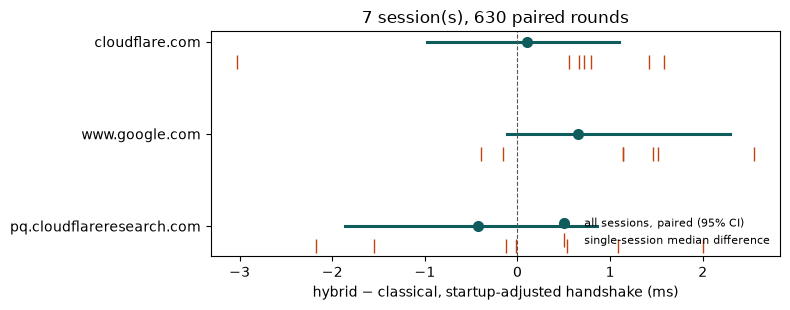

Saved per_session_summary.csv, paired_summary.csv and fig_paired.png


In [6]:
# ── 6 · Paired and multi-session analysis ───────────────────────────────
# Uses every session: the original results_qBraid_cloud.csv plus anything in
# ./sessions/. Within each round, every host was measured with both groups in
# shuffled order, so classical and hybrid can be PAIRED by
# (session, round, host). Paired differences remove round-to-round network
# drift that the unpaired comparison leaves in.
#
# Outputs: per_session_summary.csv, paired_summary.csv, fig_paired.png

import glob, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path

SEED = 20261119
B = 20000
CLASSICAL, HYBRID = "X25519", "X25519MLKEM768"

files = sorted(set(glob.glob("results_qBraid_cloud.csv") + glob.glob("sessions/session_*.csv")))
frames = []
for f in files:
    x = pd.read_csv(f)
    if "session_id" not in x:                       # the 1 Oct file predates session ids
        x["session_id"] = x.utc_start.str.replace(r"[-:]", "", regex=True).str.replace("+0000", "Z")
    frames.append(x)
data = pd.concat(frames, ignore_index=True).drop_duplicates(
    subset=["session_id", "round", "host", "group"])
data = data[data.vantage == VANTAGE] if "VANTAGE" in globals() else data
print(f"{len(files)} file(s), {data.session_id.nunique()} session(s), {len(data)} handshakes, "
      f"{(data.ok != True).sum()} failed")
ok = data[data.ok == True].copy()
assert (ok.negotiated == ok.group).all(), "a handshake negotiated a different group than requested"

# 1 · per-session summary ------------------------------------------------
per_sess = (ok.groupby(["session_id", "host", "group"])
              .agg(n=("ok", "size"), median_ms=("handshake_ms", "median"),
                   tcp_ms=("tcp_rtt_ms", "median"), colo=("cf_colo", "first"))
              .reset_index())
wide = per_sess.pivot_table(index=["session_id", "host"], columns="group",
                            values="median_ms").reset_index()
wide["diff_ms"] = wide[HYBRID] - wide[CLASSICAL]
per_sess.round(2).to_csv("per_session_summary.csv", index=False)
display(wide.round(2))

# 2 · paired differences --------------------------------------------------
pairs = (ok.pivot_table(index=["session_id", "round", "host"], columns="group",
                        values="handshake_ms").dropna().reset_index())
pairs["d"] = pairs[HYBRID] - pairs[CLASSICAL]

def cluster_boot(df, stat, rng):
    """Two-stage bootstrap: resample sessions, then rounds within each session.
    With a single session this reduces to resampling rounds."""
    sess = df.session_id.unique()
    groups = {s: df[df.session_id == s].d.values for s in sess}
    out = np.empty(B)
    for b in range(B):
        pick = rng.choice(sess, len(sess), replace=True) if len(sess) > 1 else sess
        out[b] = stat(np.concatenate([rng.choice(groups[s], len(groups[s]), replace=True) for s in pick]))
    return np.percentile(out, [2.5, 97.5])

def unpaired_boot(a, b, rng):
    return np.percentile([np.median(rng.choice(b, len(b))) - np.median(rng.choice(a, len(a)))
                          for _ in range(B)], [2.5, 97.5])

try:
    from scipy.stats import wilcoxon
except ImportError:
    wilcoxon = None

rng = np.random.default_rng(SEED)
rows = []
for h in HOSTS:
    p = pairs[pairs.host == h]
    a = ok[(ok.host == h) & (ok.group == CLASSICAL)].handshake_ms.values
    b = ok[(ok.host == h) & (ok.group == HYBRID)].handshake_ms.values
    lo_u, hi_u = unpaired_boot(a, b, rng)
    lo_p, hi_p = cluster_boot(p, np.median, rng)
    rows.append(dict(
        host=h, sessions=p.session_id.nunique(), pairs=len(p),
        classical_median=np.median(a), hybrid_median=np.median(b),
        unpaired_diff=np.median(b) - np.median(a), unpaired_lo=lo_u, unpaired_hi=hi_u,
        paired_median_diff=np.median(p.d), paired_lo=lo_p, paired_hi=hi_p,
        paired_mean_diff=p.d.mean(),
        hybrid_faster_share=(p.d < 0).mean(),
        wilcoxon_p=(wilcoxon(p.d).pvalue if wilcoxon is not None and len(p) > 5 else np.nan),
        extra_sent=ok[(ok.host == h) & (ok.group == HYBRID)].bytes_sent.median()
                   - ok[(ok.host == h) & (ok.group == CLASSICAL)].bytes_sent.median(),
        extra_recv=ok[(ok.host == h) & (ok.group == HYBRID)].bytes_recv.median()
                   - ok[(ok.host == h) & (ok.group == CLASSICAL)].bytes_recv.median(),
    ))
paired = pd.DataFrame(rows)
paired.round(3).to_csv("paired_summary.csv", index=False)
display(paired.round(2))

# 3 · figure: paired median differences + each session's median difference --
fig, ax = plt.subplots(figsize=(8, 3.2))
for i, r in paired.iterrows():
    ax.plot([r.paired_lo, r.paired_hi], [i, i], color="#0f5c5c", lw=2.2)
    ax.plot(r.paired_median_diff, i, "o", color="#0f5c5c", ms=7, zorder=3,
            label="all sessions, paired (95% CI)" if i == 0 else None)
    s = wide[wide.host == r.host].diff_ms
    ax.plot(s, [i + 0.22] * len(s), "|", color="#c2410c", ms=10,
            label="single-session median difference" if i == 0 else None)
ax.axvline(0, color="#555", lw=0.8, ls="--")
ax.set_yticks(range(len(paired))); ax.set_yticklabels(paired.host)
ax.invert_yaxis()
ax.set_xlabel("hybrid − classical, startup-adjusted handshake (ms)")
ax.set_title(f"{pairs.session_id.nunique()} session(s), {len(pairs)} paired rounds")
ax.legend(fontsize=8, loc="lower right", frameon=False)
plt.tight_layout(); plt.savefig("fig_paired.png", dpi=300); plt.show()
print("Saved per_session_summary.csv, paired_summary.csv and fig_paired.png")

## 7 · Notes for the write-up
- `handshake_ms` subtracts the measured OpenSSL start-up time, so it is an end-to-end proxy (name lookup, TCP, TLS, process exit), not a measurement of cryptographic computation. Compare groups **within** a session; differences between sessions show day-to-day path variation.
- `tcp_rtt_ms` comes from a separate Python connection made just before each handshake and includes name lookup. From session 2 onwards, `dns_ms` records the lookup time on its own.
- RFC 10024 specifies a 1,216-byte hybrid client key share (1,184 ML-KEM-768 + 32 X25519) and a 1,120-byte server key share (1,088 + 32). Relative to X25519 alone, expect +1,184 bytes in the ClientHello and +1,088 in the ServerHello. Session 1 showed +1,176 sent and +1,088 received; section 5 explains the 8-byte difference.
- A failed `X25519MLKEM768` handshake means the server did not accept the hybrid group (no fallback is possible because only one group is offered). That would itself be a finding.
- `cf_colo` is the Cloudflare data centre serving the session (an airport code). All sessions so far are expected to show IAD.
- All sessions use one vantage (qBraid cloud). The paper does not claim results for other networks or locations.